In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
 
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
 
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
 
from utils.features import (
    load_audio,
    extract_mfcc,
    extract_chroma,
    extract_spectral_centroid,
    extract_zero_crossing_rate,
    compress_features,
) 

print("All imports successful!")
print("Project folder:", root)

All imports successful!
Project folder: /Users/simonedemir/Downloads/DT2470_Project


In [2]:
data_dir = root / "dataset_clips"

 
train_df = pd.read_csv(data_dir / "train.csv")
valid_df = pd.read_csv(data_dir / "valid.csv")
test_df = pd.read_csv(data_dir / "test.csv")
 
print("Training samples:", len(train_df))
print("Validation samples:", len(valid_df))
print("Test samples:", len(test_df))
 
display(train_df.head())

Training samples: 580
Validation samples: 91
Test samples: 138


,track_id,audio_path,label,genre,artist_id,source,split,group_id
0,human_track_1267343,audio/human_track_1267343.wav,0,alternative,artist_480492,jamendo,train,human_artist_480492
1,human_track_1162016,audio/human_track_1162016.wav,0,alternative,artist_004777,jamendo,train,human_artist_004777
2,human_track_0095413,audio/human_track_0095413.wav,0,alternative,artist_000675,jamendo,train,human_artist_000675
3,human_track_1162019,audio/human_track_1162019.wav,0,alternative,artist_004777,jamendo,train,human_artist_004777
4,human_track_0006495,audio/human_track_0006495.wav,0,alternative,artist_000675,jamendo,train,human_artist_000675


In [3]:
def extract_svm_features(audio_path):
    
    y, sr = load_audio(audio_path)

    # Extract features
    mfcc = extract_mfcc(y, sr)
    chroma = extract_chroma(y, sr)
    centroid = extract_spectral_centroid(y, sr)
    zcr = extract_zero_crossing_rate(y, sr)

    # Combine compressed features
    return np.concatenate([
        compress_features(mfcc),
        compress_features(chroma),
        compress_features(centroid),
        compress_features(zcr)
    ])



In [4]:
# Directory for cached SVM features
cache_dir = root / "artifacts" / "svm_features"
cache_dir.mkdir(parents=True, exist_ok=True)

def build_feature_matrix(df, split_name):
    cache_file = cache_dir / f"{split_name}_features.npz"

    # Reuse previously extracted features
    if cache_file.exists():
        cached = np.load(cache_file)
        return cached["X"], cached["y"]

    X = []
    y = []

    for i, (_, row) in enumerate(df.iterrows(), start=1):
        audio_path = data_dir / row["audio_path"]

        features = extract_svm_features(audio_path)

        X.append(features)
        y.append(int(row["label"]))


    X = np.asarray(X)
    y = np.asarray(y)

    np.savez_compressed(cache_file, X=X, y=y)
    print(f"Saved {split_name} features to {cache_file}")

    return X, y


X_train, y_train = build_feature_matrix(train_df, "train")
X_valid, y_valid = build_feature_matrix(valid_df, "valid")
X_test, y_test = build_feature_matrix(test_df, "test")

print("\nFinal shapes:")
print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)


Final shapes:
Train: (580, 68) (580,)
Valid: (91, 68) (91,)
Test: (138, 68) (138,)


In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
 
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)


In [6]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
 
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale")

# Train the model using training data
svm_model.fit(X_train_scaled, y_train)
 
y_valid_pred = svm_model.predict(X_valid_scaled)
 
accuracy = accuracy_score(y_valid, y_valid_pred)

print("Validation accuracy:", round(accuracy, 4))
print("\nClassification report:")
print(classification_report(
    y_valid,
    y_valid_pred,
    target_names=["Human", "AI"]
))

print("Confusion matrix:")
print(confusion_matrix(y_valid, y_valid_pred))

Validation accuracy: 0.967

Classification report:
              precision    recall  f1-score   support

       Human       0.97      0.98      0.98        62
          AI       0.96      0.93      0.95        29

    accuracy                           0.97        91
   macro avg       0.97      0.96      0.96        91
weighted avg       0.97      0.97      0.97        91

Confusion matrix:
[[61  1]
 [ 2 27]]


In [7]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# Train a linear SVM for comparison
linear_svm = SVC(kernel="linear", C=1.0)
linear_svm.fit(X_train_scaled, y_train)
 
y_valid_linear = linear_svm.predict(X_valid_scaled)
 
print("RBF SVM accuracy:",
      accuracy_score(y_valid, y_valid_pred))

print("Linear SVM accuracy:",
      accuracy_score(y_valid, y_valid_linear))

print("\nLinear SVM confusion matrix:")
print(confusion_matrix(y_valid, y_valid_linear))

RBF SVM accuracy: 0.967032967032967
Linear SVM accuracy: 0.967032967032967

Linear SVM confusion matrix:
[[59  3]
 [ 0 29]]


In [8]:
# Feature groups based on our extraction order
feature_groups = {
    "MFCC": (0, 40),
    "Chroma": (40, 64),
    "Spectral centroid": (64, 66),
    "Zero-crossing rate": (66, 68),
}

results = []

for feature_name, (start, end) in feature_groups.items():
 
    X_train_group = X_train[:, start:end]
    X_valid_group = X_valid[:, start:end]
 
    group_scaler = StandardScaler()
    X_train_group = group_scaler.fit_transform(X_train_group)
    X_valid_group = group_scaler.transform(X_valid_group)
 
    model = SVC(kernel="linear", C=1.0)
    model.fit(X_train_group, y_train)
 
    predictions = model.predict(X_valid_group)
    accuracy = accuracy_score(y_valid, predictions)

    results.append({
        "Feature": feature_name,
        "Number of features": end - start,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

display(results_df)

,Feature,Number of features,Accuracy
0,MFCC,40,0.989011
1,Chroma,24,0.637363
2,Spectral centroid,2,0.417582
3,Zero-crossing rate,2,0.428571


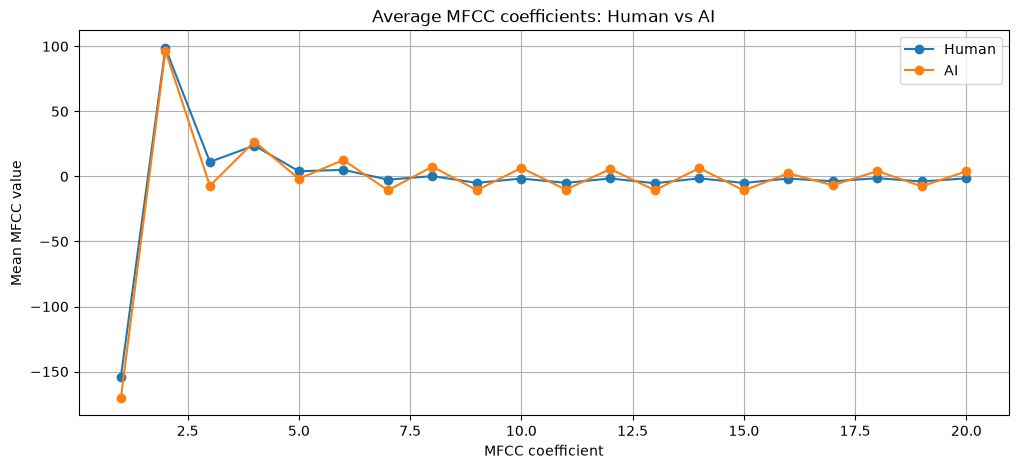

In [9]:
import matplotlib.pyplot as plt
 
mfcc_human = X_train[y_train == 0, :20]
mfcc_ai = X_train[y_train == 1, :20]

# Average each coefficient across all training clips
human_mean = mfcc_human.mean(axis=0)
ai_mean = mfcc_ai.mean(axis=0)

plt.figure(figsize=(12, 5))

plt.plot(range(1, 21), human_mean, marker="o", label="Human")
plt.plot(range(1, 21), ai_mean, marker="o", label="AI")

plt.xlabel("MFCC coefficient")
plt.ylabel("Mean MFCC value")
plt.title("Average MFCC coefficients: Human vs AI")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# Compare standardized differences between MFCC coefficients
mfcc_human = X_train[y_train == 0, :20]
mfcc_ai = X_train[y_train == 1, :20]

human_mean = mfcc_human.mean(axis=0)
ai_mean = mfcc_ai.mean(axis=0)

human_var = mfcc_human.var(axis=0, ddof=1)
ai_var = mfcc_ai.var(axis=0, ddof=1)

 
pooled_std = np.sqrt((human_var + ai_var) / 2)
 
effect_size = np.divide(
    ai_mean - human_mean,
    pooled_std,
    out=np.zeros_like(ai_mean),
    where=pooled_std > 0
)

effect_df = pd.DataFrame({
    "MFCC": np.arange(1, 21),
    "Effect size": effect_size,
    "Absolute effect size": np.abs(effect_size)
})

display(
    effect_df.sort_values(
        "Absolute effect size",
        ascending=False
    ).head(10)
)

,MFCC,Effect size,Absolute effect size
13,14,1.415715,1.415715
19,20,1.238795,1.238795
6,7,-1.227429,1.227429
14,15,-1.223392,1.223392
11,12,1.182566,1.182566
17,18,1.175240,1.175240
9,10,1.086124,1.086124
12,13,-1.078946,1.078946
2,3,-1.030229,1.030229
8,9,-0.936393,0.936393


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
 
X_test_scaled = scaler.transform(X_test)
 
y_test_pred = svm_model.predict(X_test_scaled)
 
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
 
tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
).ravel()

fpr = fp / (fp + tn)

print("Final SVM Test Results")
print("----------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"False positive rate: {fpr:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_test_pred))

Final SVM Test Results
----------------------
Accuracy: 0.9638
Precision: 1.0000
Recall: 0.9296
F1-score: 0.9635
False positive rate: 0.0000

Confusion matrix:
[[67  0]
 [ 5 66]]
